# 02 - Feature Engineering
Raw sensor values se aise features banate hain jo machine ki condition (trend, variability, load) dikhate hain.
Saare rolling features sirf **pichli** readings se bante hain, future ka data use nahi hota (leakage se bachne ke liye).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # notebook 'notebooks/' folder se chal raha hai
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config
sns.set_theme(style="whitegrid")

from src.preprocessing import load_raw, clean, add_features, add_rul
df = add_rul(add_features(clean(load_raw())))
df[[config.COL_MACHINE, config.COL_TIME] + config.FEATURES + ['rul']].head(15)

,machine_id,timestamp,temperature,air_temperature,temp_diff,rotational_speed,torque,tool_wear,type_code,power,torque_speed_ratio,temp_roll_mean,temp_roll_std,temp_delta,temp_slope,torque_roll_mean,torque_delta,speed_roll_std,wear_rate,rul
0,M001,2026-01-01 00:00:00,310.44,301.18,9.26,1554.0,35.94,39.0,1,5848.677910,0.023127,310.440000,0.000000,0.00,0.000000,35.940000,0.00,0.000000,0.0,22.0
1,M001,2026-01-01 01:00:00,311.61,301.46,10.15,1627.0,35.04,42.0,1,5970.081617,0.021537,311.025000,0.827315,1.17,1.170000,35.490000,-0.90,51.618795,3.0,21.0
2,M001,2026-01-01 02:00:00,311.52,302.08,9.44,1529.0,36.93,43.0,1,5913.102551,0.024153,311.190000,0.651076,-0.09,0.540000,35.970000,1.89,50.921508,1.0,20.0
3,M001,2026-01-01 03:00:00,311.08,301.80,9.28,1636.0,39.83,46.0,1,6823.736117,0.024346,311.162500,0.534439,-0.44,0.183000,36.935000,2.90,53.081698,3.0,19.0
4,M001,2026-01-01 04:00:00,312.27,303.02,9.25,1480.0,36.99,49.0,1,5732.903938,0.024993,311.384000,0.677886,1.19,0.313000,36.946000,-2.84,66.194411,3.0,18.0
5,M001,2026-01-01 05:00:00,311.23,302.24,8.99,1433.0,43.41,50.0,1,6514.252588,0.030293,311.358333,0.609571,-1.04,0.156857,38.023333,6.42,80.113461,1.0,17.0
6,M001,2026-01-01 06:00:00,311.69,301.86,9.83,1457.0,41.45,53.0,1,6324.303519,0.028449,311.405714,0.570405,0.46,0.133571,38.512857,-1.96,80.057122,3.0,16.0
7,M001,2026-01-01 07:00:00,312.28,302.63,9.65,1658.0,38.37,54.0,1,6662.004833,0.023142,311.515000,0.611906,0.59,0.161905,38.495000,-3.08,86.684568,1.0,15.0
8,M001,2026-01-01 08:00:00,310.92,301.58,9.34,1486.0,37.61,57.0,1,5852.625845,0.025310,311.448889,0.605773,-1.36,0.073667,38.396667,-0.76,83.576312,3.0,14.0
9,M001,2026-01-01 09:00:00,311.74,301.63,10.11,1304.0,41.01,57.0,1,5600.102533,0.031449,311.478000,0.578500,0.82,0.069455,38.658000,3.40,108.528747,0.0,13.0


## Check: rolling feature future ko nahi dekhta
Pehli 8 rows se banaya gaya feature poore data wale feature ke barabar hona chahiye.

In [2]:
one = clean(load_raw())
one = one[one[config.COL_MACHINE] == one[config.COL_MACHINE].iloc[0]]
full = add_features(one)['temp_roll_mean'].iloc[7]
short = add_features(one.iloc[:8])['temp_roll_mean'].iloc[7]
print(full, short, 'same' if abs(full - short) < 1e-9 else 'LEAK!')

311.515 311.515 same


## Engineered features vs failure

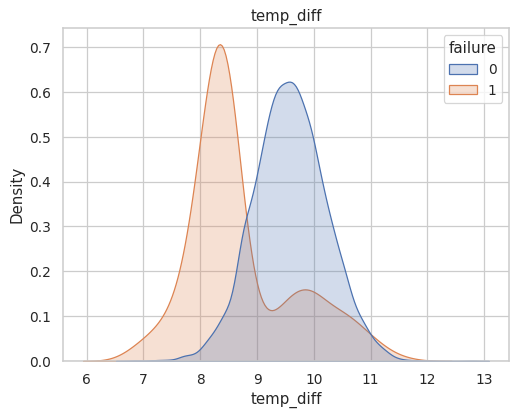

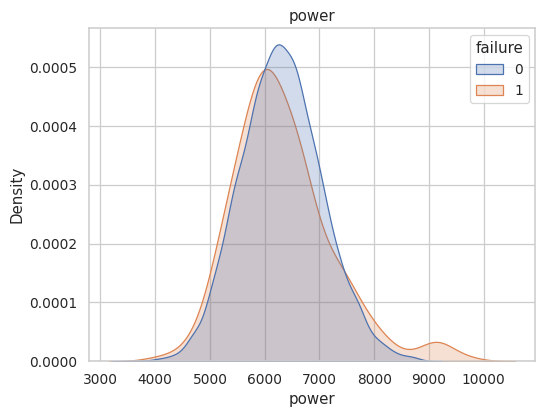

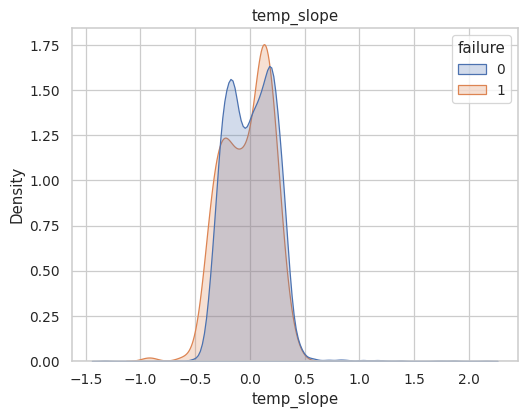

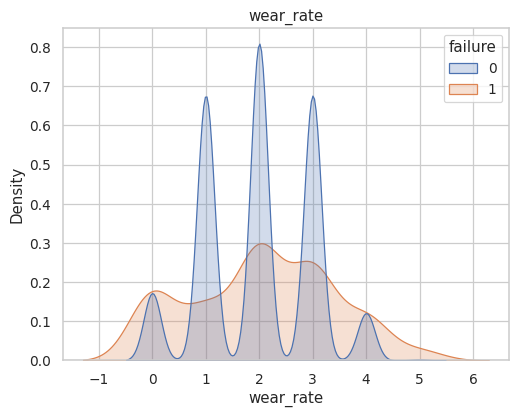

In [3]:
for col in ['temp_diff', 'power', 'temp_slope', 'wear_rate']:
    sns.kdeplot(data=df, x=col, hue=config.COL_FAILURE, common_norm=False, fill=True)
    plt.title(col)
    plt.show()

## Remaining Useful Life (RUL)
Agle failure me kitni readings bachi hain (cap = `config.RUL_CAP`).

count    10000.000000
mean        21.637500
std         10.716342
min          0.000000
25%         12.000000
50%         30.000000
75%         30.000000
max         30.000000
Name: rul, dtype: float64


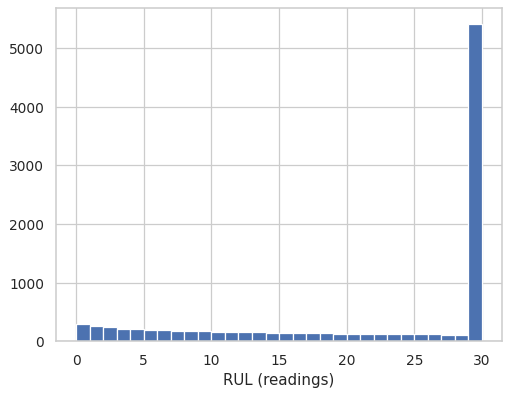

In [4]:
print(df['rul'].describe())
df['rul'].hist(bins=30)
plt.xlabel('RUL (readings)')
plt.show()

## Har feature kyun banaya? (justification table)

| Feature | Formula | Kyun useful |
|---|---|---|
| `temp_diff` | process temp - air temp | Cooling theek kaam kar rahi hai ya nahi (heat dissipation failure) |
| `power` | torque x rpm x 2pi/60 | Motor/drive ka actual load (power failure) |
| `torque_speed_ratio` | torque / rpm | Load ka relative level, speed normalise karke |
| `temp_roll_mean`, `temp_roll_std` | last 10 readings ka mean / std | Noise hata kar level aur instability dikhata hai |
| `temp_delta` | current - previous temp | Achanak jump |
| `temp_slope` | last 10 readings par line fit | Slow degradation / garam hote jaana |
| `torque_roll_mean`, `torque_delta` | rolling mean, diff | Load trend |
| `speed_roll_std` | rpm ki rolling std | Speed instability |
| `wear_rate` | tool_wear diff | Tool kitni tezi se ghis raha hai |

Ek single reading se degradation nahi dikhta, trend features **time ke saath badlav** pakadte hain.

## Features ka failure se relation (mutual information)
Mutual information non-linear relation bhi pakadta hai, isliye correlation se zyada reliable hai.

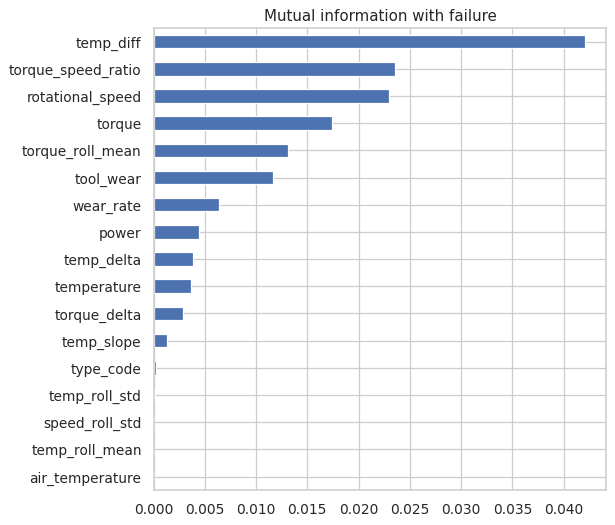

In [5]:
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(df[config.FEATURES], df[config.COL_FAILURE], random_state=42),
               index=config.FEATURES).sort_values()
mi.plot(kind='barh', figsize=(7,6)); plt.title('Mutual information with failure'); plt.tight_layout(); plt.show()

## Engineered features ka correlation heatmap
Jo features bahut zyada correlated hain (jaise `temperature` aur `temp_roll_mean`) unka overlap tree-based models handle kar lete hain.

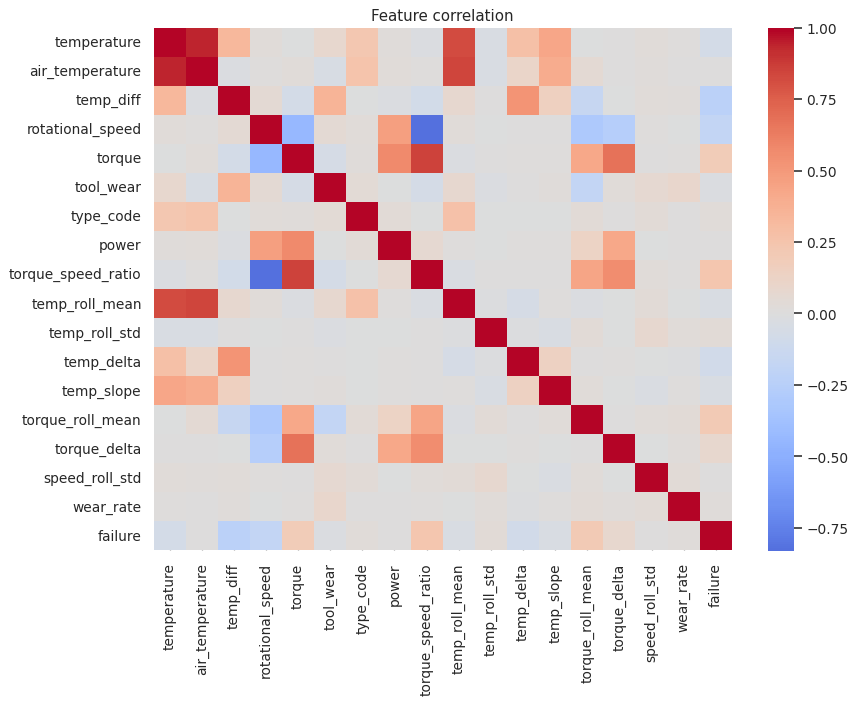

In [6]:
plt.figure(figsize=(10,8))
sns.heatmap(df[config.FEATURES + [config.COL_FAILURE]].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Feature correlation'); plt.tight_layout(); plt.show()

## Leakage rules (summary)
- Rolling/diff/slope features sirf **past** readings se bante hain.
- Upar wale check me 8-row wali history aur poore data se bana feature same aaya -> future data use nahi hua.
- Split time ke hisaab se hota hai (notebook 03).